In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df=pd.read_csv('fare.csv')

In [2]:
df

,trip_duration,distance_traveled,num_of_passengers,fare,tip,miscellaneous_fees,surge_applied
0,748,2.75,1,75.00,24,6.300,0
1,1187,3.43,1,105.00,24,13.200,0
2,730,3.12,1,71.25,0,26.625,1
3,671,5.63,3,90.00,0,9.750,0
4,329,2.09,1,45.00,12,13.200,0
...,...,...,...,...,...,...,...
209668,1617,8.42,1,150.00,47,5.800,0
209669,438,1.29,1,48.75,12,34.575,1
209670,571,2.82,1,63.75,0,6.000,0
209671,491,2.16,1,56.25,0,13.500,0


In [3]:
df.head()

,trip_duration,distance_traveled,num_of_passengers,fare,tip,miscellaneous_fees,surge_applied
0,748,2.75,1,75.00,24,6.300,0
1,1187,3.43,1,105.00,24,13.200,0
2,730,3.12,1,71.25,0,26.625,1
3,671,5.63,3,90.00,0,9.750,0
4,329,2.09,1,45.00,12,13.200,0


In [4]:
df.columns

Index(['trip_duration', 'distance_traveled', 'num_of_passengers', 'fare',
       'tip', 'miscellaneous_fees', 'surge_applied'],
      dtype='str')

In [10]:
df.isnull().sum()

trip_duration         0
distance_traveled     0
num_of_passengers     0
fare                  0
tip                   0
miscellaneous_fees    0
surge_applied         0
dtype: int64

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import statsmodels.api as sm

In [12]:
df.describe()

,trip_duration,distance_traveled,num_of_passengers,fare,tip,miscellaneous_fees,surge_applied
count,209673.000000,209673.000000,209673.000000,209673.000000,209673.000000,209673.000000,209673.000000
mean,1173.181478,5.054431,1.292808,99.623431,13.030824,15.136829,0.280523
std,4775.653621,125.217419,0.930754,85.602702,20.367764,12.553436,0.449256
min,0.000000,0.020000,0.000000,0.000000,0.000000,-0.500000,0.000000
25%,446.000000,1.950000,1.000000,52.500000,0.000000,6.000000,0.000000
50%,707.000000,3.200000,1.000000,75.000000,9.000000,9.750000,0.000000
75%,1098.000000,5.730000,1.000000,116.250000,20.000000,26.450000,1.000000
max,86387.000000,57283.910000,9.000000,4466.250000,2500.000000,435.000000,1.000000


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 209673 entries, 0 to 209672
Data columns (total 7 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   trip_duration       209673 non-null  int64  
 1   distance_traveled   209673 non-null  float64
 2   num_of_passengers   209673 non-null  int64  
 3   fare                209673 non-null  float64
 4   tip                 209673 non-null  int64  
 5   miscellaneous_fees  209673 non-null  float64
 6   surge_applied       209673 non-null  int64  
dtypes: float64(3), int64(4)
memory usage: 11.2 MB


In [15]:
df.shape #209673- datapoint 7-column

(209673, 7)

In [16]:
df.dtypes

trip_duration           int64
distance_traveled     float64
num_of_passengers       int64
fare                  float64
tip                     int64
miscellaneous_fees    float64
surge_applied           int64
dtype: object

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 209673 entries, 0 to 209672
Data columns (total 7 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   trip_duration       209673 non-null  int64  
 1   distance_traveled   209673 non-null  float64
 2   num_of_passengers   209673 non-null  int64  
 3   fare                209673 non-null  float64
 4   tip                 209673 non-null  int64  
 5   miscellaneous_fees  209673 non-null  float64
 6   surge_applied       209673 non-null  int64  
dtypes: float64(3), int64(4)
memory usage: 11.2 MB


In [19]:
df_trip=df[df['trip_duration']==0]
df_trip

,trip_duration,distance_traveled,num_of_passengers,fare,tip,miscellaneous_fees,surge_applied
1762,0,0.02,1,187.50,0,2.250,0
3074,0,0.18,1,18.75,38,9.250,0
4108,0,0.16,2,600.00,0,2.250,0
4535,0,0.02,1,18.75,0,13.500,0
12418,0,0.06,2,225.00,45,2.700,0
15019,0,7.19,1,138.75,0,9.750,0
36462,0,0.06,2,352.50,71,2.200,0
46617,0,0.11,1,18.75,15,6.000,0
51024,0,0.05,1,45.00,0,2.250,0
51257,0,0.43,1,300.00,60,2.700,0


In [21]:
df_trip[['trip_duration','distance_traveled']]

,trip_duration,distance_traveled
1762,0,0.02
3074,0,0.18
4108,0,0.16
4535,0,0.02
12418,0,0.06
15019,0,7.19
36462,0,0.06
46617,0,0.11
51024,0,0.05
51257,0,0.43


In [22]:
df_trip[['trip_duration','distance_traveled','num_of_passengers','fare']]

,trip_duration,distance_traveled,num_of_passengers,fare
1762,0,0.02,1,187.50
3074,0,0.18,1,18.75
4108,0,0.16,2,600.00
4535,0,0.02,1,18.75
12418,0,0.06,2,225.00
15019,0,7.19,1,138.75
36462,0,0.06,2,352.50
46617,0,0.11,1,18.75
51024,0,0.05,1,45.00
51257,0,0.43,1,300.00


In [3]:
df1=df.copy() #have a copy and remove in df1

In [24]:
df_trip_indexes=df_trip.index
df_trip_indexes # bold in data set 

Index([  1762,   3074,   4108,   4535,  12418,  15019,  36462,  46617,  51024,
        51257,  57763,  65008,  69620,  75746,  80323,  82499,  85904,  98332,
       130369, 131446, 139456, 140179, 144462, 154787, 174252, 181260, 181484,
       189435, 189685, 190278, 201019, 203692, 208249],
      dtype='int64')

In [25]:
print('Before Removing',df1.shape)
df1.drop(index = df_trip_indexes,axis=0, inplace= True)
print('After Removing',df1.shape)

Before Removing (209673, 7)
After Removing (209640, 7)


In [26]:
df1.describe()

,trip_duration,distance_traveled,num_of_passengers,fare,tip,miscellaneous_fees,surge_applied
count,209640.000000,209640.000000,209640.000000,209640.000000,209640.000000,209640.000000,209640.000000
mean,1173.366151,5.055155,1.292835,99.614249,13.030137,15.138474,0.280562
std,4776.006797,125.227260,0.930815,85.587195,20.367089,12.553499,0.449275
min,1.000000,0.020000,0.000000,0.000000,0.000000,-0.500000,0.000000
25%,446.000000,1.950000,1.000000,52.500000,0.000000,6.000000,0.000000
50%,707.000000,3.220000,1.000000,75.000000,9.000000,9.750000,0.000000
75%,1098.000000,5.730000,1.000000,116.250000,20.000000,26.450000,1.000000
max,86387.000000,57283.910000,9.000000,4466.250000,2500.000000,435.000000,1.000000


In [6]:
df_distance=df1[df1['distance_traveled']==57283.910000]
df_distance

,trip_duration,distance_traveled,num_of_passengers,fare,tip,miscellaneous_fees,surge_applied
197339,1734,57283.91,1,187.125,20,50.875,0


In [28]:
df1.drop(index=197339,axis=0,inplace=True)

In [30]:
df_passengers=df1[df1['num_of_passengers']==0]
df_passengers

,trip_duration,distance_traveled,num_of_passengers,fare,tip,miscellaneous_fees,surge_applied
14,234,1.61,0,37.50,0,26.625,1
380,584,1.93,0,60.00,0,34.125,1
426,1548,4.02,0,123.75,0,26.625,1
459,471,2.90,0,60.00,21,9.375,0
1523,436,2.09,0,52.50,15,5.625,0
...,...,...,...,...,...,...,...
208592,1148,4.67,0,108.75,27,26.625,1
208679,240,0.97,0,33.75,8,33.625,1
208707,2443,6.92,0,0.00,0,0.000,0
208909,656,2.74,0,67.50,15,5.625,0


In [31]:
df_passengers_indexes=df_passengers.index
df_passengers_indexes

Index([    14,    380,    426,    459,   1523,   1836,   2130,   2336,   2461,
         2496,
       ...
       207263, 207539, 208084, 208488, 208504, 208592, 208679, 208707, 208909,
       209017],
      dtype='int64', length=753)

In [32]:
df1.drop(index=df_passengers_indexes,axis=0,inplace=True)

In [33]:
df1

,trip_duration,distance_traveled,num_of_passengers,fare,tip,miscellaneous_fees,surge_applied
0,748,2.75,1,75.00,24,6.300,0
1,1187,3.43,1,105.00,24,13.200,0
2,730,3.12,1,71.25,0,26.625,1
3,671,5.63,3,90.00,0,9.750,0
4,329,2.09,1,45.00,12,13.200,0
...,...,...,...,...,...,...,...
209668,1617,8.42,1,150.00,47,5.800,0
209669,438,1.29,1,48.75,12,34.575,1
209670,571,2.82,1,63.75,0,6.000,0
209671,491,2.16,1,56.25,0,13.500,0


In [34]:
df1

,trip_duration,distance_traveled,num_of_passengers,fare,tip,miscellaneous_fees,surge_applied
14,234,1.61,0,37.50,0,26.625,1
380,584,1.93,0,60.00,0,34.125,1
426,1548,4.02,0,123.75,0,26.625,1
459,471,2.90,0,60.00,21,9.375,0
1523,436,2.09,0,52.50,15,5.625,0
...,...,...,...,...,...,...,...
208592,1148,4.67,0,108.75,27,26.625,1
208679,240,0.97,0,33.75,8,33.625,1
208707,2443,6.92,0,0.00,0,0.000,0
208909,656,2.74,0,67.50,15,5.625,0


In [38]:
df1.describe()

,trip_duration,distance_traveled,num_of_passengers,fare,tip,miscellaneous_fees,surge_applied
count,208886.000000,208886.000000,208886.000000,208886.00000,208886.000000,208886.000000,208886.000000
mean,1174.738963,4.783911,1.297497,99.64512,13.026560,15.130716,0.280225
std,4784.436728,5.633013,0.929246,85.57457,20.354571,12.547661,0.449110
min,1.000000,0.020000,1.000000,0.00000,0.000000,-0.500000,0.000000
25%,446.000000,1.950000,1.000000,52.50000,0.000000,6.000000,0.000000
50%,707.000000,3.220000,1.000000,75.00000,9.000000,9.750000,0.000000
75%,1099.000000,5.730000,1.000000,116.25000,20.000000,26.450000,1.000000
max,86387.000000,1136.500000,9.000000,4466.25000,2500.000000,435.000000,1.000000


In [40]:
df1.shape

(208886, 7)

In [41]:
df1.columns

Index(['trip_duration', 'distance_traveled', 'num_of_passengers', 'fare',
       'tip', 'miscellaneous_fees', 'surge_applied'],
      dtype='str')

In [43]:
df1.drop(['tip','miscellaneous_fees'],axis=1,inplace=True)

In [44]:
df1.head()

,trip_duration,distance_traveled,num_of_passengers,fare,surge_applied
0,748,2.75,1,75.00,0
1,1187,3.43,1,105.00,0
2,730,3.12,1,71.25,1
3,671,5.63,3,90.00,0
4,329,2.09,1,45.00,0


<Axes: >

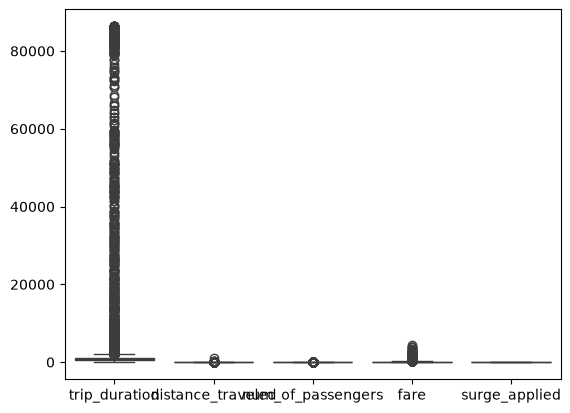

In [45]:
sns.boxplot(df1)

In [46]:
df1.describe()

,trip_duration,distance_traveled,num_of_passengers,fare,surge_applied
count,208886.000000,208886.000000,208886.000000,208886.00000,208886.000000
mean,1174.738963,4.783911,1.297497,99.64512,0.280225
std,4784.436728,5.633013,0.929246,85.57457,0.449110
min,1.000000,0.020000,1.000000,0.00000,0.000000
25%,446.000000,1.950000,1.000000,52.50000,0.000000
50%,707.000000,3.220000,1.000000,75.00000,0.000000
75%,1099.000000,5.730000,1.000000,116.25000,1.000000
max,86387.000000,1136.500000,9.000000,4466.25000,1.000000


In [58]:
Q1 = df['trip_duration'].quantile(0.25)
Q3 = df['trip_duration'].quantile(0.75)
IQR = Q3 - Q1
print('IQR',IQR) 
lower_fence=Q1-(1.5*IQR)
upper_fence=Q3+(1.5*IQR)
print('Lower Fence:',lower_fence)
print('upper_fence:',upper_fence)

IQR 652.0
Lower Fence: -532.0
upper_fence: 2076.0


In [55]:
df1['num_of_passengers'].unique()

array([1, 3, 2, 6, 5, 4, 8, 7, 9])

In [59]:
df1['num_of_passengers'].value_counts()

num_of_passengers
1    179199
2     17892
5      4713
6      3382
3      2757
4       908
8        25
9         8
7         2
Name: count, dtype: int64

In [60]:
shapes=df1.shape[0]

numeric_column=['trip_duration','distance_traveled']

for i in numeric_column:
    print(i,'-->',shapes)
    q1=df1[i].quantile(0.25)
    q3=df1[i].quantile(0.75)
    iqr=q3-q1

    upper_fence=q3+(1.5*iqr)
    lower_fence=q1-(1.5*iqr)

    outliers=df1[(df1[i]<lower_fence) | (df1[i]>upper_fence)].index
    df1.drop(outliers,axis=0,inplace=True)

    print(f"Processing {i}")
    print(f"Before removing outliers shape: {shapes}")
    print(f"After removing the outlilers shape: {df1.shape[0]}")

trip_duration --> 208886
Processing trip_duration
Before removing outliers shape: 208886
After removing the outlilers shape: 197045
distance_traveled --> 208886
Processing distance_traveled
Before removing outliers shape: 208886
After removing the outlilers shape: 182709


In [61]:
df1.to_csv('fare_processes_data.csv')

In [62]:
pwd

'C:\\Users\\hp\\OneDrive\\Documents\\ML'